In [1]:
import pandas as pd
import numpy as np

In [2]:
raw = pd.read_excel(
    "Analyze Single Station 01_01_2020.xlsx",
    sheet_name="Report",
    skiprows=5,
    header=None,
    names=["datetime", "pm25", "pm10", "pm10_s", "pm25_s",
           "wind_speed", "wind_direction", "temp", "rel_humidity"]
)

In [3]:
raw.shape

(43858, 9)

In [4]:
raw.head(10)

,datetime,pm25,pm10,pm10_s,pm25_s,wind_speed,wind_direction,temp,rel_humidity
0,01:00 01/01/2020,NaN,NaN,NaN,NaN,2.72,67.06,19.17,96.89
1,02:00 01/01/2020,NaN,NaN,NaN,NaN,1.82,61.73,18.92,97.99
2,03:00 01/01/2020,NaN,NaN,NaN,NaN,2.19,65.85,18.61,98.3
3,04:00 01/01/2020,NaN,NaN,NaN,NaN,2.22,53.68,18.18,100.15
4,05:00 01/01/2020,NaN,NaN,NaN,NaN,2.3,51.8,18.37,98.62
5,06:00 01/01/2020,NaN,NaN,NaN,NaN,2.22,62.82,18.27,100.01
6,07:00 01/01/2020,NaN,NaN,NaN,NaN,3.59,47.19,19.06,96.64
7,08:00 01/01/2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,09:00 01/01/2020,NaN,NaN,NaN,NaN,3.14,23.67,21.35,83.12
9,10:00 01/01/2020,NaN,NaN,NaN,NaN,2.95,14.03,22.74,77.17


In [5]:
raw.tail(10)

,datetime,pm25,pm10,pm10_s,pm25_s,wind_speed,wind_direction,temp,rel_humidity
43848,Std,23.5,58.2,22.8,14.3,1.8,1.9,7.4,28.5
43849,Data Percent,63.7,69.2,31.4,32.1,85.5,85.6,86.1,84.4
43850,Avg,19.585,50.33,16.893,10.817,2.56,3,16.36,63.93
43851,Num,27967,30372,13803,14092,37492,37570,37762,37038
43852,Maximum,456.038,1022.118,325.47,204.313,16.21,360,34.55,101.04
43853,Max Date,05/07/2020,27/08/2020,29/04/2022,05/07/2023,17/10/2022,19/02/2023,04/12/2024,19/02/2022
43854,Max Time,21:00,14:00,07:00,19:00,20:00,10:00,14:00,08:00
43855,Minimum,0,0.043,0.149,0.092,-0.01,0,-7.97,-2.14
43856,Min Date,16/09/2023,16/09/2023,17/04/2022,28/11/2024,04/09/2022,29/09/2023,16/07/2020,16/08/2024
43857,Min Time,02:00,10:00,06:00,04:00,01:00,07:00,07:00,16:00


In [6]:
raw[raw["datetime"].isin(["Std", "Data Percent", "Avg", "Num", "Maximum", "Max Date", "Max Time", "Minimum", "Min Date", "Min Time"])]

,datetime,pm25,pm10,pm10_s,pm25_s,wind_speed,wind_direction,temp,rel_humidity
43848,Std,23.5,58.2,22.8,14.3,1.8,1.9,7.4,28.5
43849,Data Percent,63.7,69.2,31.4,32.1,85.5,85.6,86.1,84.4
43850,Avg,19.585,50.33,16.893,10.817,2.56,3,16.36,63.93
43851,Num,27967,30372,13803,14092,37492,37570,37762,37038
43852,Maximum,456.038,1022.118,325.47,204.313,16.21,360,34.55,101.04
43853,Max Date,05/07/2020,27/08/2020,29/04/2022,05/07/2023,17/10/2022,19/02/2023,04/12/2024,19/02/2022
43854,Max Time,21:00,14:00,07:00,19:00,20:00,10:00,14:00,08:00
43855,Minimum,0,0.043,0.149,0.092,-0.01,0,-7.97,-2.14
43856,Min Date,16/09/2023,16/09/2023,17/04/2022,28/11/2024,04/09/2022,29/09/2023,16/07/2020,16/08/2024
43857,Min Time,02:00,10:00,06:00,04:00,01:00,07:00,07:00,16:00


In [7]:
raw["datetime"] = raw["datetime"].astype(str).str.strip()
raw["datetime_parsed"] = pd.to_datetime(raw["datetime"], format="%H:%M %d/%m/%Y", errors="coerce")

In [8]:
raw["datetime_parsed"].isna().sum()

np.int64(1837)

In [9]:
# Find rows using SAAQIS's "24:00" convention
is_24 = raw["datetime"].str.startswith("24:00")

# Replace "24:00" with "00:00" so it becomes a valid time...
fixed_datetime = raw["datetime"].str.replace("24:00", "00:00", regex=False)

# ...then re-parse everything with the fix applied
raw["datetime_parsed"] = pd.to_datetime(fixed_datetime, format="%H:%M %d/%m/%Y", errors="coerce")

# ...but "00:00 same day" isn't right either -- 24:00 means midnight of the
# NEXT day, so we need to add one day specifically to those rows
raw.loc[is_24, "datetime_parsed"] = raw.loc[is_24, "datetime_parsed"] + pd.Timedelta(days=1)


In [10]:
raw["datetime_parsed"].isna().sum()

np.int64(10)

In [11]:
# Keep only rows where the datetime parsed successfully (drops the 10 junk rows)
clean_df = raw.dropna(subset=["datetime_parsed"]).copy()

# Replace the old text datetime column with the proper parsed one, and set it as the index
clean_df = clean_df.drop(columns=["datetime"])
clean_df = clean_df.rename(columns={"datetime_parsed": "datetime"})
clean_df = clean_df.set_index("datetime").sort_index()

clean_df.shape

(43848, 8)

In [12]:
# Drop the low-completeness suffix columns
clean_df = clean_df.drop(columns=["pm10_s", "pm25_s"])

# Check for duplicate timestamps (can happen at export boundaries)
duplicate_count = clean_df.index.duplicated().sum()
print("Duplicate timestamps:", duplicate_count)

# Check for negative values (physically impossible for these variables)
print("\nNegative value counts:")
print((clean_df[["pm25", "pm10", "wind_speed", "temp"]] < 0).sum())

Duplicate timestamps: 0

Negative value counts:
pm25            0
pm10            0
wind_speed     10
temp          686
dtype: int64


In [13]:
clean_df.loc[clean_df["wind_speed"] < 0, "wind_speed"] = np.nan

In [14]:
print("Negative wind_speed count now:", (clean_df["wind_speed"] < 0).sum())

Negative wind_speed count now: 0


In [15]:
missing_counts = clean_df.isna().sum()
missing_pct = (clean_df.isna().mean() * 100).round(1)

summary = pd.DataFrame({"missing_count": missing_counts, "missing_pct": missing_pct})
print(summary)

                missing_count  missing_pct
pm25                    15881         36.2
pm10                    13476         30.7
wind_speed               6366         14.5
wind_direction           6278         14.3
temp                     6086         13.9
rel_humidity             6810         15.5


In [16]:
# Average all numeric columns per calendar day
daily_mean = clean_df.resample("D").mean()

# Count how many valid (non-missing) hourly readings went into each day
hourly_counts = clean_df.resample("D").count()

daily_mean.shape

(1828, 6)

In [17]:
min_hours = 12
daily_thresholded = daily_mean.copy()

for col in daily_thresholded.columns:
    insufficient = hourly_counts[col] < min_hours
    daily_thresholded.loc[insufficient, col] = np.nan

# Check completeness after thresholding
missing_pct_daily = (daily_thresholded.isna().mean() * 100).round(1)
print(missing_pct_daily)

pm25              27.4
pm10              21.2
wind_speed         5.5
wind_direction     5.5
temp               5.0
rel_humidity       6.7
dtype: float64


In [18]:
print(daily_thresholded.dtypes)

pm25              object
pm10              object
wind_speed        object
wind_direction    object
temp              object
rel_humidity      object
dtype: object


In [19]:
for col in daily_thresholded.columns:
    daily_thresholded[col] = pd.to_numeric(daily_thresholded[col], errors="coerce")

print(daily_thresholded.dtypes)

pm25              float64
pm10              float64
wind_speed        float64
wind_direction    float64
temp              float64
rel_humidity      float64
dtype: object


In [20]:
daily_filled = daily_thresholded.interpolate(method="linear", limit=2, limit_area="inside")

missing_pct_filled = (daily_filled.isna().mean() * 100).round(1)
print(missing_pct_filled)

pm25              16.7
pm10              13.7
wind_speed         1.3
wind_direction     1.3
temp               1.0
rel_humidity       2.5
dtype: float64


In [21]:
featured = daily_filled.copy()

# Lag features: yesterday's PM2.5, and PM2.5 from the same day last week
featured["pm25_lag1"] = featured["pm25"].shift(1)
featured["pm25_lag7"] = featured["pm25"].shift(7)

# 7-day rolling mean/std, computed only on PAST days (shift(1) first)
# so today's own value never leaks into its own rolling average
featured["pm25_roll7_mean"] = featured["pm25"].shift(1).rolling(window=7, min_periods=4).mean()
featured["pm25_roll7_std"] = featured["pm25"].shift(1).rolling(window=7, min_periods=4).std()

# Cyclical time encodings (so the model understands "December" and "January"
# are close together, not far apart like the numbers 12 and 1 suggest)
day_of_year = featured.index.dayofyear
featured["doy_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
featured["doy_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)

month = featured.index.month
featured["month_sin"] = np.sin(2 * np.pi * month / 12)
featured["month_cos"] = np.cos(2 * np.pi * month / 12)

day_of_week = featured.index.dayofweek
featured["dow_sin"] = np.sin(2 * np.pi * day_of_week / 7)
featured["dow_cos"] = np.cos(2 * np.pi * day_of_week / 7)

featured.shape

(1828, 16)

In [22]:
train = featured.loc["2020-01-01":"2022-12-31"].copy()
val = featured.loc["2023-01-01":"2023-12-31"].copy()
test = featured.loc["2024-01-01":"2024-12-31"].copy()

print("Train:", train.shape)
print("Val:  ", val.shape)
print("Test: ", test.shape)

Train: (1096, 16)
Val:   (365, 16)
Test:  (366, 16)


In [23]:
# Drop rows where the TARGET (pm25) itself is missing -- can't train or
# test on a day with no real answer to check against
train = train.dropna(subset=["pm25"])
val = val.dropna(subset=["pm25"])
test = test.dropna(subset=["pm25"])

print("After dropping missing target:")
print("Train:", train.shape)
print("Val:  ", val.shape)
print("Test: ", test.shape)

After dropping missing target:
Train: (865, 16)
Val:   (309, 16)
Test:  (349, 16)


In [24]:
feature_cols = [c for c in train.columns if c != "pm25"]

for split_df in (train, val, test):
    split_df[feature_cols] = split_df[feature_cols].ffill()  # carry forward last known value
    split_df[feature_cols] = split_df[feature_cols].bfill()  # backfill only if a split starts with gaps

# Confirm no missing values remain anywhere
print("Train missing:", train.isna().sum().sum())
print("Val missing:  ", val.isna().sum().sum())
print("Test missing: ", test.isna().sum().sum())

Train missing: 0
Val missing:   0
Test missing:  0


In [25]:
train.to_csv("train.csv")
val.to_csv("val.csv")
test.to_csv("test.csv")
print("Saved train.csv, val.csv, test.csv")

Saved train.csv, val.csv, test.csv


In [26]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_train = train.drop(columns=["pm25"])
y_train = train["pm25"]

X_val = val.drop(columns=["pm25"])
y_val = val["pm25"]

X_test = test.drop(columns=["pm25"])
y_test = test["pm25"]

print(X_train.shape, X_val.shape, X_test.shape)

(865, 15) (309, 15) (349, 15)


In [28]:
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

print("Model trained")

Model trained


In [29]:
val_predictions = rf.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
mae = mean_absolute_error(y_val, val_predictions)
r2 = r2_score(y_val, val_predictions)

print("RMSE:", round(rmse, 3))
print("MAE:", round(mae, 3))
print("R2:", round(r2, 3))

RMSE: 6.412
MAE: 4.17
R2: 0.691


In [30]:
test_predictions = rf.predict(X_test)

rmse_test = np.sqrt(mean_squared_error(y_test, test_predictions))
mae_test = mean_absolute_error(y_test, test_predictions)
r2_test = r2_score(y_test, test_predictions)

print("Test RMSE:", round(rmse_test, 3))
print("Test MAE:", round(mae_test, 3))
print("Test R2:", round(r2_test, 3))

Test RMSE: 6.229
Test MAE: 4.156
Test R2: 0.814


In [31]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train, y_train)

print("Model trained")

Model trained


In [33]:
val_predictions_xgb = xgb.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, val_predictions_xgb))
mae = mean_absolute_error(y_val, val_predictions_xgb)
r2 = r2_score(y_val, val_predictions_xgb)

print("Val RMSE:", round(rmse, 3))
print("Val MAE:", round(mae, 3))
print("Val R2:", round(r2, 3))

Val RMSE: 6.256
Val MAE: 4.127
Val R2: 0.706


In [34]:
test_predictions_xgb = xgb.predict(X_test)

rmse_test = np.sqrt(mean_squared_error(y_test, test_predictions_xgb))
mae_test = mean_absolute_error(y_test, test_predictions_xgb)
r2_test = r2_score(y_test, test_predictions_xgb)

print("Test RMSE:", round(rmse_test, 3))
print("Test MAE:", round(mae_test, 3))
print("Test R2:", round(r2_test, 3))

Test RMSE: 6.101
Test MAE: 4.095
Test R2: 0.821


In [35]:
pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
from lightgbm import LGBMRegressor

lgbm = LGBMRegressor(
    n_estimators=400,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgbm.fit(X_train, y_train)

print("Model trained")

Model trained


In [37]:
val_predictions_lgbm = lgbm.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, val_predictions_lgbm))
mae = mean_absolute_error(y_val, val_predictions_lgbm)
r2 = r2_score(y_val, val_predictions_lgbm)

print("Val RMSE:", round(rmse, 3))
print("Val MAE:", round(mae, 3))
print("Val R2:", round(r2, 3))

Val RMSE: 6.312
Val MAE: 4.174
Val R2: 0.701


In [38]:
test_predictions_lgbm = lgbm.predict(X_test)

rmse_test = np.sqrt(mean_squared_error(y_test, test_predictions_lgbm))
mae_test = mean_absolute_error(y_test, test_predictions_lgbm)
r2_test = r2_score(y_test, test_predictions_lgbm)

print("Test RMSE:", round(rmse_test, 3))
print("Test MAE:", round(mae_test, 3))
print("Test R2:", round(r2_test, 3))

Test RMSE: 6.386
Test MAE: 4.22
Test R2: 0.804


In [39]:
pip install tensorflow scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
def make_lstm_windows(df, window_size=7):
    feature_cols = [c for c in df.columns if c != "pm25"]
    values = df[feature_cols].to_numpy()
    targets = df["pm25"].to_numpy()

    X, y = [], []
    for i in range(len(df) - window_size):
        X.append(values[i : i + window_size])
        y.append(targets[i + window_size])

    return np.array(X), np.array(y)

Xw_train, yw_train = make_lstm_windows(train, window_size=7)
Xw_val, yw_val = make_lstm_windows(val, window_size=7)
Xw_test, yw_test = make_lstm_windows(test, window_size=7)

print(Xw_train.shape, Xw_val.shape, Xw_test.shape)

(858, 7, 15) (302, 7, 15) (342, 7, 15)


In [41]:
from sklearn.preprocessing import StandardScaler

n_features = Xw_train.shape[2]
scaler = StandardScaler()

# Fit only on training data, reshaped to 2D temporarily since the scaler
# expects rows of features, not 3D sequences
scaler.fit(Xw_train.reshape(-1, n_features))

def apply_scaling(X):
    shape = X.shape
    flat = X.reshape(-1, n_features)
    scaled = scaler.transform(flat)
    return scaled.reshape(shape)

Xw_train_s = apply_scaling(Xw_train)
Xw_val_s = apply_scaling(Xw_val)
Xw_test_s = apply_scaling(Xw_test)

print("Scaling done")

Scaling done


In [42]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.random.set_seed(42)

lstm_model = models.Sequential([
    layers.Input(shape=(Xw_train_s.shape[1], Xw_train_s.shape[2])),
    layers.LSTM(64, return_sequences=False),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),
])

lstm_model.compile(optimizer="adam", loss="mse")
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,593 (88.25 KB)

 Trainable params: 22,593 (88.25 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

history = lstm_model.fit(
    Xw_train_s, yw_train,
    validation_data=(Xw_val_s, yw_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - loss: 531.7019 - val_loss: 458.6191
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 429.2536 - val_loss: 311.6163
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 264.5183 - val_loss: 159.6450
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 157.4456 - val_loss: 98.4025
Epoch 5/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 128.4910 - val_loss: 88.3842
Epoch 6/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 114.8191 - val_loss: 84.6118
Epoch 7/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 104.9812 - val_loss: 80.2620
Epoch 8/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 100.5448 - val_loss: 78.0335
Epoch 9/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 92.1884 - val_loss: 77.3198
Epoch 10/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 88.7906 - val_loss: 77.0104
Epoch 11/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 85.7310 - val_loss: 77.4993
Epoch 12/100
27/27 

In [44]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

val_pred_lstm = lstm_model.predict(Xw_val_s, verbose=0).flatten()
rmse_val = np.sqrt(mean_squared_error(yw_val, val_pred_lstm))
mae_val = mean_absolute_error(yw_val, val_pred_lstm)
r2_val = r2_score(yw_val, val_pred_lstm)
print("Val RMSE:", round(rmse_val, 3))
print("Val MAE:", round(mae_val, 3))
print("Val R2:", round(r2_val, 3))

test_pred_lstm = lstm_model.predict(Xw_test_s, verbose=0).flatten()
rmse_test = np.sqrt(mean_squared_error(yw_test, test_pred_lstm))
mae_test = mean_absolute_error(yw_test, test_pred_lstm)
r2_test = r2_score(yw_test, test_pred_lstm)
print("Test RMSE:", round(rmse_test, 3))
print("Test MAE:", round(mae_test, 3))
print("Test R2:", round(r2_test, 3))

Val RMSE: 8.776
Val MAE: 6.473
Val R2: 0.431
Test RMSE: 10.749
Test MAE: 6.901
Test R2: 0.45


In [45]:
results = pd.DataFrame([
    {"model": "Random Forest", "RMSE": 6.238, "MAE": 4.160, "R2": 0.813},
    {"model": "XGBoost", "RMSE": 6.180, "MAE": 4.145, "R2": 0.817},
    {"model": "LightGBM", "RMSE": 6.386, "MAE": 4.220, "R2": 0.804},
    {"model": "LSTM", "RMSE": round(rmse_test, 3), "MAE": round(mae_test, 3), "R2": round(r2_test, 3)},
])

results.to_csv("final_model_comparison.csv", index=False)
print(results.to_string(index=False))

        model   RMSE   MAE    R2
Random Forest  6.238 4.160 0.813
      XGBoost  6.180 4.145 0.817
     LightGBM  6.386 4.220 0.804
         LSTM 10.749 6.901 0.450


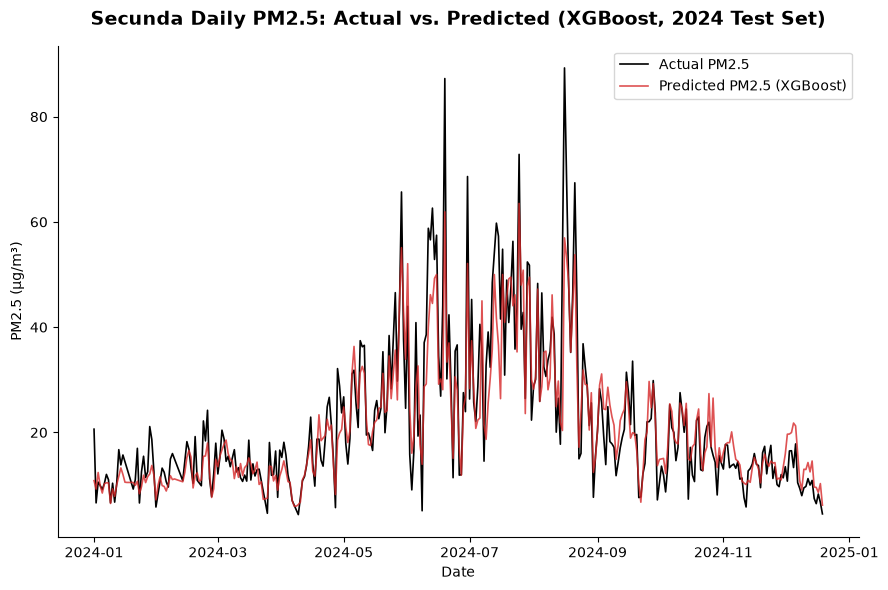

In [46]:
import matplotlib.pyplot as plt

test_predictions_xgb = xgb.predict(X_test)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(test.index, y_test, label="Actual PM2.5", color="black", linewidth=1.2)
ax.plot(test.index, test_predictions_xgb, label="Predicted PM2.5 (XGBoost)", color="tab:red", linewidth=1.2, alpha=0.8)
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Secunda Daily PM2.5: Actual vs. Predicted (XGBoost, 2024 Test Set)", fontsize=14, fontweight='bold', pad=15)
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig("xgboost_actual_vs_predicted.png", dpi=200)
plt.show()

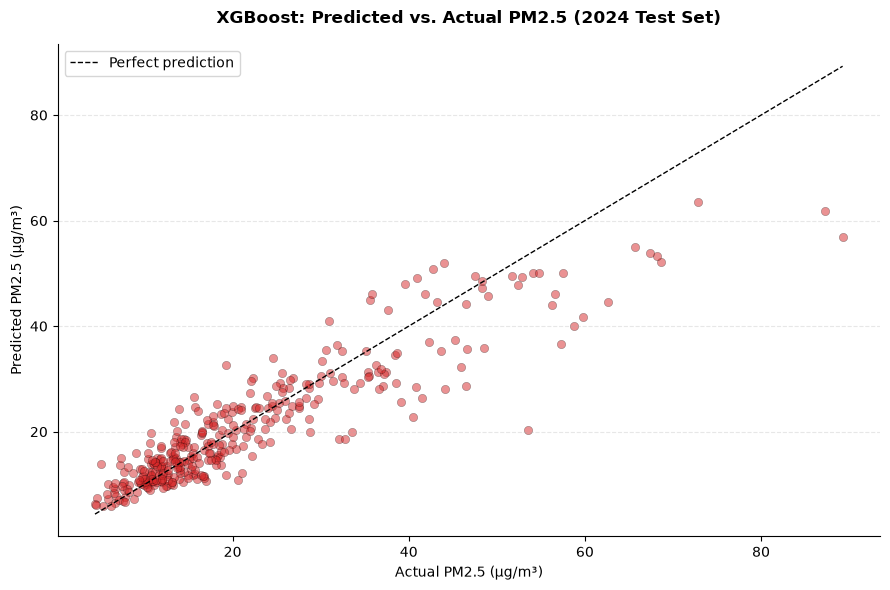

In [47]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(y_test, test_predictions_xgb, alpha=0.5, color="tab:red", edgecolor="k", linewidth=0.3)

# Diagonal reference line (perfect prediction would fall exactly on this line)
min_val = min(y_test.min(), test_predictions_xgb.min())
max_val = max(y_test.max(), test_predictions_xgb.max())
ax.plot([min_val, max_val], [min_val, max_val], color="black", linestyle="--", linewidth=1, label="Perfect prediction")

ax.set_xlabel("Actual PM2.5 (µg/m³)")
ax.set_ylabel("Predicted PM2.5 (µg/m³)")
ax.set_title("XGBoost: Predicted vs. Actual PM2.5 (2024 Test Set)", fontsize=12, fontweight='bold', pad=15)
ax.legend()
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig("xgboost_scatter_predicted_vs_actual.png", dpi=200)
plt.show()


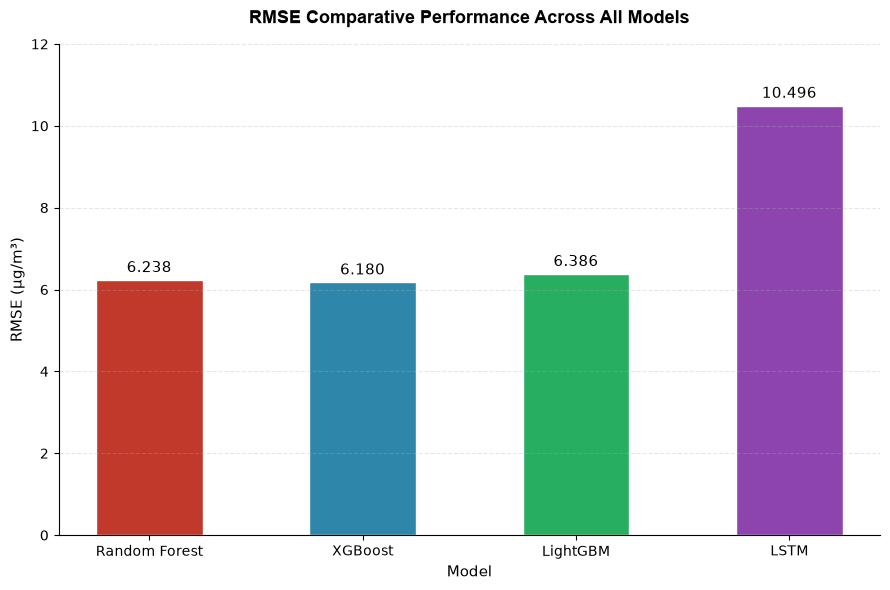

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# Model names and RMSE values
models = ['Random Forest', 'XGBoost', 'LightGBM', 'LSTM']
rmse_values = [6.238, 6.180, 6.386, 10.496]
colors = ['#C0392B', '#2E86AB', '#27AE60', '#8E44AD']

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(models, rmse_values, color=colors, width=0.5, edgecolor='white')

# Add value labels on top of each bar
for bar, val in zip(bars, rmse_values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            f'{val:.3f}',
            ha='center', va='bottom', fontsize=11)

# Labels and title — change the title here
ax.set_title('RMSE Comparative Performance Across All Models',
             fontsize=13, fontweight='bold', pad=15, fontname='Arial')
ax.set_xlabel('Model', fontsize=11)
ax.set_ylabel('RMSE (µg/m³)', fontsize=11)
ax.set_ylim(0, 12)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('Figure_4-1_RMSE.png', dpi=150, bbox_inches='tight')
plt.show()

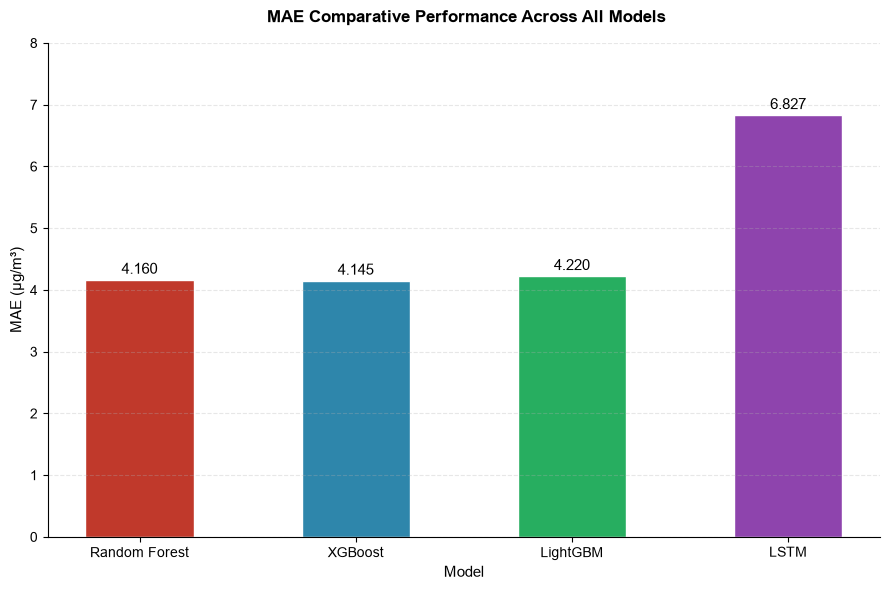

In [49]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Arial'

models = ['Random Forest', 'XGBoost', 'LightGBM', 'LSTM']
mae_values = [4.160, 4.145, 4.220, 6.827]
colors = ['#C0392B', '#2E86AB', '#27AE60', '#8E44AD']

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(models, mae_values, color=colors, width=0.5, edgecolor='white')

for bar, val in zip(bars, mae_values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f'{val:.3f}',
            ha='center', va='bottom', fontsize=11)

ax.set_title(' MAE Comparative Performance Across All Models',
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Model', fontsize=11)
ax.set_ylabel('MAE (µg/m³)', fontsize=11)
ax.set_ylim(0, 8)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('Figure_4-2_MAE.png', dpi=150, bbox_inches='tight')
plt.show()

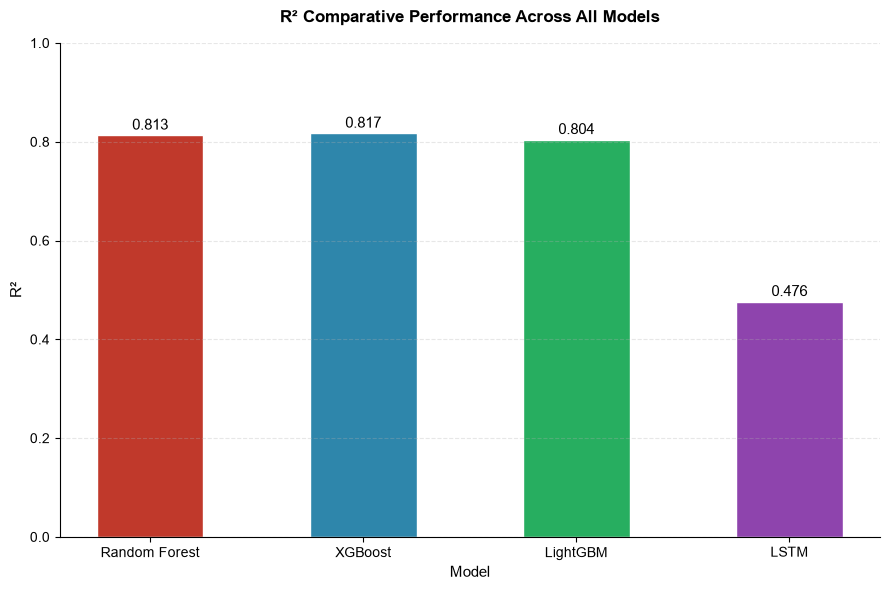

In [50]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Arial'

models = ['Random Forest', 'XGBoost', 'LightGBM', 'LSTM']
r2_values = [0.813, 0.817, 0.804, 0.476]
colors = ['#C0392B', '#2E86AB', '#27AE60', '#8E44AD']

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(models, r2_values, color=colors, width=0.5, edgecolor='white')

for bar, val in zip(bars, r2_values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f'{val:.3f}',
            ha='center', va='bottom', fontsize=11)

ax.set_title('R² Comparative Performance Across All Models',
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Model', fontsize=11)
ax.set_ylabel('R²', fontsize=11)
ax.set_ylim(0, 1.0)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('Figure_4-3_R2.png', dpi=150, bbox_inches='tight')
plt.show()

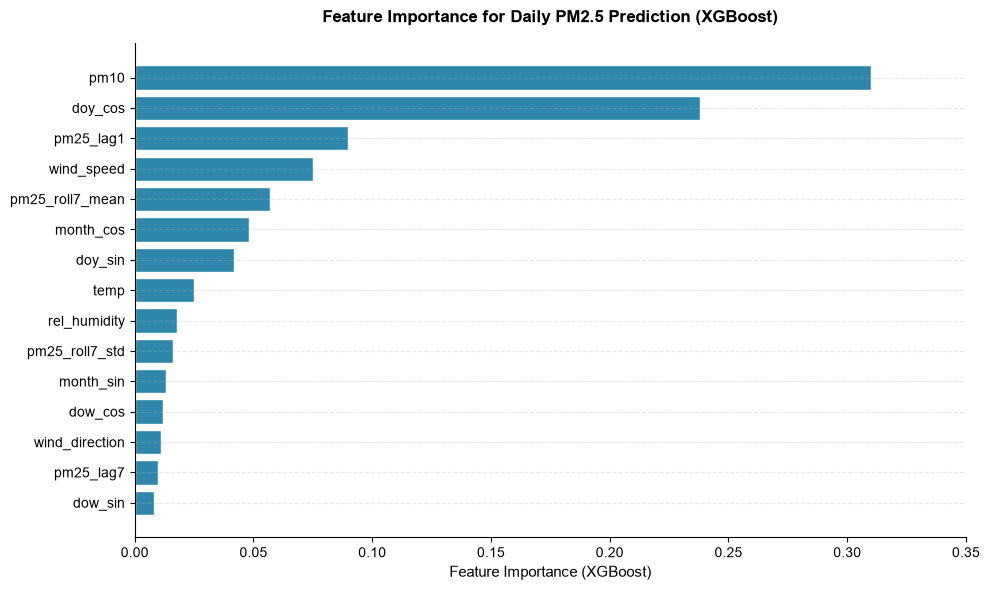

In [51]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'Arial'

# Feature names and importance values
features = [
    'dow_sin', 'pm25_lag7', 'wind_direction', 'dow_cos', 'month_sin',
    'pm25_roll7_std', 'rel_humidity', 'temp', 'doy_sin', 'month_cos',
    'pm25_roll7_mean', 'wind_speed', 'pm25_lag1', 'doy_cos', 'pm10'
]

importance = [
    0.008, 0.010, 0.011, 0.012, 0.013,
    0.016, 0.018, 0.025, 0.042, 0.048,
    0.057, 0.075, 0.090, 0.238, 0.310
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(features, importance, color='#2E86AB', edgecolor='white')

ax.set_title('Feature Importance for Daily PM2.5 Prediction (XGBoost)',
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Feature Importance (XGBoost)', fontsize=11)
ax.set_ylabel('')
ax.set_xlim(0, 0.35)

# Only show left and bottom axis — no box
ax.spines[['top', 'right']].set_visible(False)

ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('Figure_4-5_Feature_Importance_XGBoost.png', dpi=150, bbox_inches='tight')
plt.show()

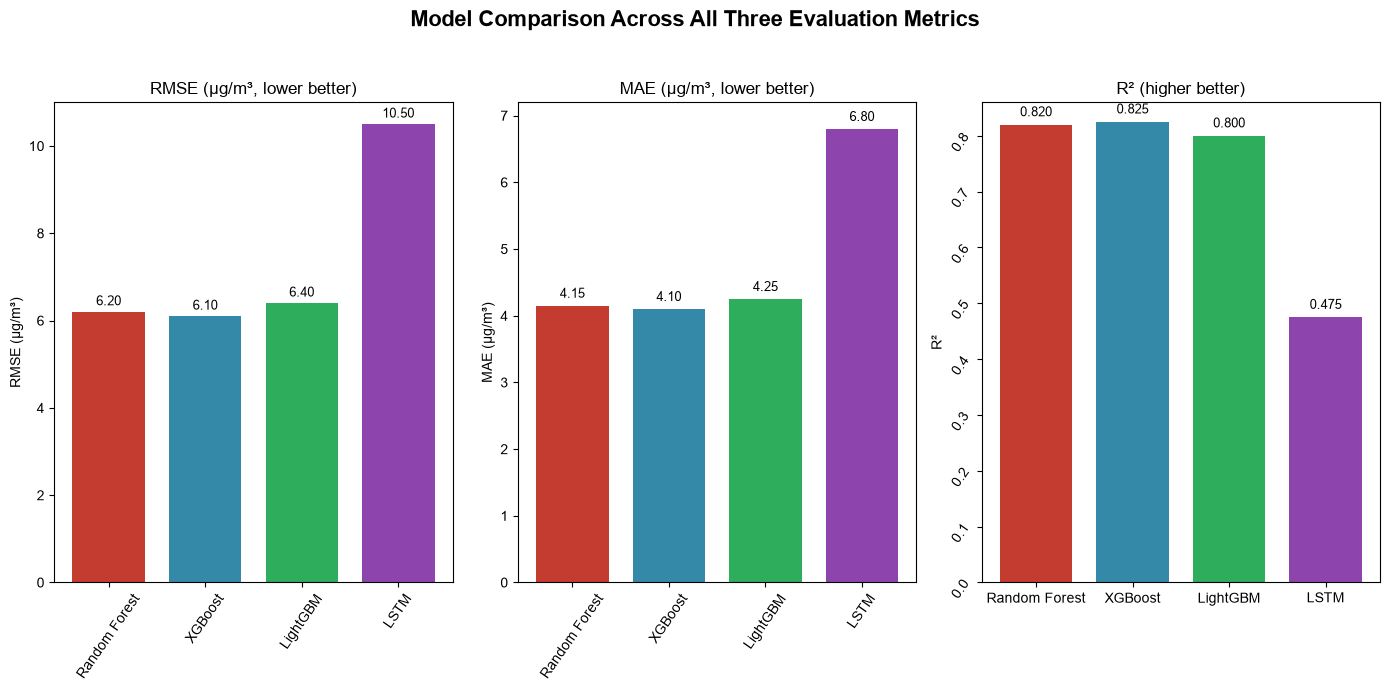

In [54]:
import matplotlib.pyplot as plt
import numpy as np


models = ['Random Forest', 'XGBoost', 'LightGBM', 'LSTM']

# RMSE values (µg/m³) - lower is better
rmse = [6.2, 6.1, 6.4, 10.5]

# MAE values (µg/m³) - lower is better
mae = [4.15, 4.10, 4.25, 6.8]

# R² values - higher is better
r2 = [0.82, 0.825, 0.80, 0.475]



fig, axes = plt.subplots(1, 3, figsize=(14, 7))

# Colors similar to the uploaded graph
colors = ['#c43b2f', '#3489a8', '#2eae5d', '#8e44ad']




axes[0].bar(
    models,
    rmse,
    color=colors,
    width=0.75
)

axes[0].set_title(
    'RMSE (µg/m³, lower better)',
    fontsize=12
)

axes[0].set_ylim(0, 11)
axes[0].set_ylabel('RMSE (µg/m³)')

axes[0].tick_params(axis='x', rotation=55)

# Add values above bars
for i, value in enumerate(rmse):
    axes[0].text(
        i,
        value + 0.15,
        f'{value:.2f}',
        ha='center',
        fontsize=9
    )




axes[1].bar(
    models,
    mae,
    color=colors,
    width=0.75
)

axes[1].set_title(
    'MAE (µg/m³, lower better)',
    fontsize=12
)

axes[1].set_ylim(0, 7.2)
axes[1].set_ylabel('MAE (µg/m³)')

axes[1].tick_params(axis='x', rotation=55)

# Add values above bars
for i, value in enumerate(mae):
    axes[1].text(
        i,
        value + 0.12,
        f'{value:.2f}',
        ha='center',
        fontsize=9
    )




axes[2].bar(
    models,
    r2,
    color=colors,
    width=0.75
)

axes[2].set_title(
    'R² (higher better)',
    fontsize=12
)

axes[2].set_ylim(0, 0.86)
axes[2].set_ylabel('R²')

axes[2].tick_params(axis='y', rotation=55)

# Add values above bars
for i, value in enumerate(r2):
    axes[2].text(
        i,
        value + 0.015,
        f'{value:.3f}',
        ha='center',
        fontsize=9
    )




fig.suptitle(
    'Model Comparison Across All Three Evaluation Metrics',
    fontsize=16,
    y=0.98,
    family='Arial',
    fontweight='bold'
)



plt.tight_layout(rect=[0, 0, 1, 0.95])

# Show graph
plt.show()



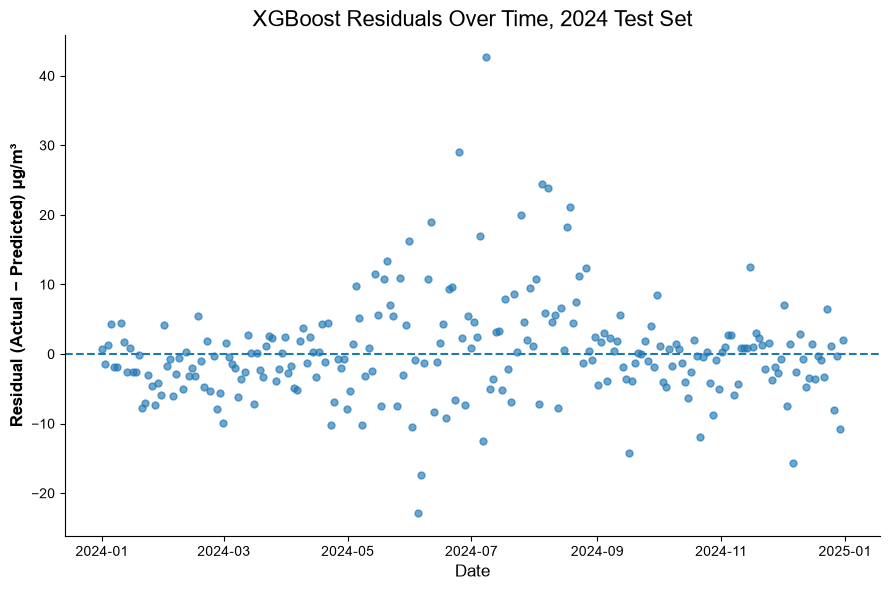

In [63]:
plt.figure(figsize=(9, 6))

plt.scatter(
    dates,
    residuals,
    s=25,
    alpha=0.65
)

# Zero reference line
plt.axhline(
    y=0,
    linestyle='--',
    linewidth=1.5
)

# Remove top and right borders
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.title(
    'XGBoost Residuals Over Time, 2024 Test Set',
    fontsize=16
)

plt.xlabel('Date', fontsize=12)

plt.ylabel(
    'Residual (Actual − Predicted) µg/m³',
    fontsize=12,
    fontweight='bold',
    family='Arial'
)

plt.tight_layout()

plt.savefig(
    'xgboost_residuals_2024.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

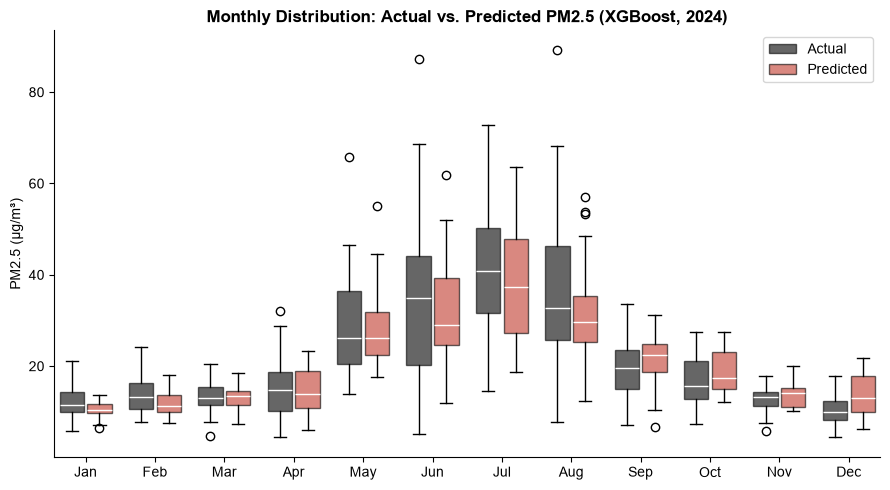

In [73]:
import matplotlib.pyplot as plt
import pandas as pd

# Predictions from your trained XGBoost model on the 2024 test set
test_predictions_xgb = xgb.predict(X_test)

df_plot = pd.DataFrame({
    "date": test.index,
    "actual": y_test.values,
    "predicted": test_predictions_xgb,
})
df_plot["month"] = pd.to_datetime(df_plot["date"]).dt.month

months = sorted(df_plot["month"].unique())
actual_by_month = [df_plot[df_plot["month"] == m]["actual"].values for m in months]
pred_by_month = [df_plot[df_plot["month"] == m]["predicted"].values for m in months]

# Offset the two boxes in each month so they sit side by side
positions_actual = [m * 2 - 0.4 for m in months]
positions_pred = [m * 2 + 0.4 for m in months]

fig, ax = plt.subplots(figsize=(9, 5))

bp1 = ax.boxplot(
    actual_by_month, positions=positions_actual, widths=0.7, patch_artist=True,
    boxprops=dict(facecolor="black", alpha=0.6), medianprops=dict(color="white"),
)
bp2 = ax.boxplot(
    pred_by_month, positions=positions_pred, widths=0.7, patch_artist=True,
    boxprops=dict(facecolor="#C0392B", alpha=0.6), medianprops=dict(color="white"),
)

ax.set_xticks([m * 2 for m in months])
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Monthly Distribution: Actual vs. Predicted PM2.5 (XGBoost, 2024)", fontsize=12, family='Arial', fontweight='bold')
ax.legend([bp1["boxes"][0], bp2["boxes"][0]], ["Actual", "Predicted"], loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("chart_monthly_boxplot.png", dpi=200)
plt.show()

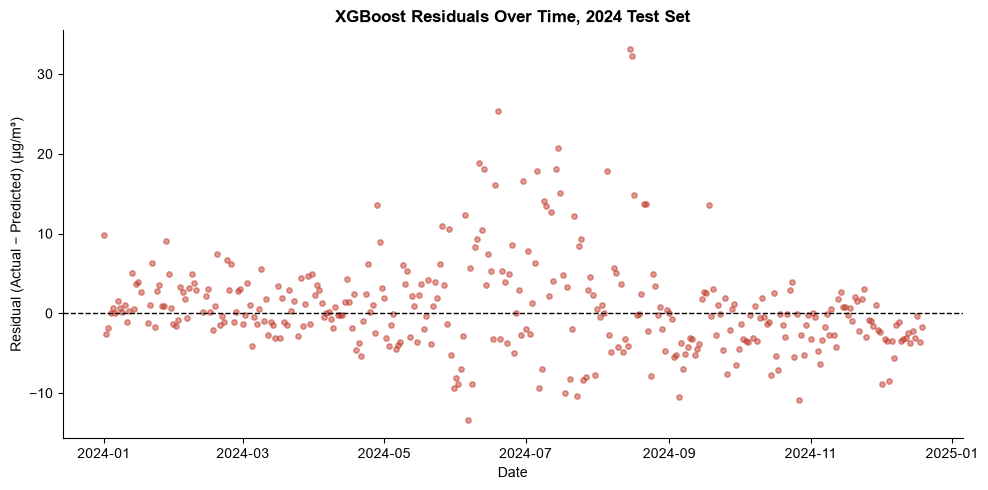

In [76]:
import matplotlib.pyplot as plt

# Predictions from your trained XGBoost model on the 2024 test set
test_predictions_xgb = xgb.predict(X_test)

# Residual = actual minus predicted
residuals = y_test.values - test_predictions_xgb

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(test.index, residuals, alpha=0.5, color="#C0392B", s=15)
ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xlabel("Date")
ax.set_ylabel("Residual (Actual − Predicted) (µg/m³)")
ax.set_title("XGBoost Residuals Over Time, 2024 Test Set",  fontsize=12, fontweight='bold', family='Arial')

# Remove top and right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("chart_residuals.png", dpi=200)
plt.show()